# Listening history and memory

What evidence does the workbook give us for a lasting preference? These 300 listeners are synthetic. We look at event quality, the amount of history per listener, and how the type of evidence changes across the three product surfaces. Workbook memory and golden sheets are reference annotations.

Run the cells from top to bottom with the workbook in the project's `data` folder. Each row in Events is a delivery. One underlying action can be delivered twice.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

paths = [Path("data/listening_memory.xlsx"), Path("../data/listening_memory.xlsx")]
file = next(p for p in paths if p.exists())
users = pd.read_excel(file, sheet_name="Users")
events = pd.read_excel(file, sheet_name="Events")
memories = pd.read_excel(file, sheet_name="Memories")
gold = pd.read_excel(file, sheet_name="Golden Cases")
print("Listeners:", users.subject_id.nunique())
print("Event deliveries:", len(events))
print("Reference memory versions:", len(memories))
print("Golden queries:", len(gold))

Listeners: 300
Event deliveries: 664
Reference memory versions: 277
Golden queries: 81


## 1. Check the recording unit

A missing utterance can be valid for a playback signal. Check the fields required for every event separately. A listener and an idempotency key identify one action even if a new delivery receives a different event ID.

In [2]:
required = ["event_id", "subject_id", "event_type", "event_at", "idempotency_key"]
print("Missing values by required field")
print(events[required].isna().sum().to_string())
print("Unknown listeners:", (~events.subject_id.isin(users.subject_id)).sum())
print("Duplicate event IDs:", events.event_id.duplicated().sum())
key = ["subject_id", "idempotency_key"]
retries = events[events.duplicated(key, keep=False)]
print("Deliveries in repeated-key groups")
print(retries[key + ["event_id", "event_type"]].sort_values(key).to_string(index=False))
clean = events.sort_values("received_at").drop_duplicates(key, keep="first").copy()
print("Unique actions:", len(clean))

Missing values by required field
event_id           0
subject_id         0
event_type         0
event_at           0
idempotency_key    0
Unknown listeners: 0
Duplicate event IDs: 0
Deliveries in repeated-key groups
subject_id idempotency_key event_id          event_type
     U0058   IDEM-E0058-01 E0058-01 explicit_preference
     U0058   IDEM-E0058-01 E0058-02 explicit_preference
     U0059   IDEM-E0059-01 E0059-01 explicit_preference
     U0059   IDEM-E0059-01 E0059-02 explicit_preference
     U0060   IDEM-E0060-01 E0060-01 explicit_preference
     U0060   IDEM-E0060-01 E0060-02 explicit_preference
Unique actions: 661


All required fields are present. The repeated keys belong to three explicit-preference actions. Counting both deliveries would inflate the number of preference statements from 198 to 201.

## 2. Which actions dominate the dataset?

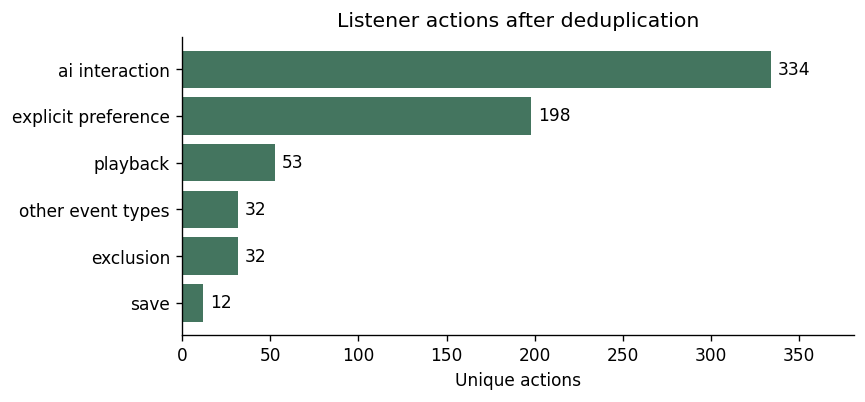

In [3]:
counts = clean.event_type.value_counts()
main = counts.head(5).copy()
main.loc["other event types"] = counts.iloc[5:].sum()
main = main.sort_values()
fig, ax = plt.subplots(figsize=(7.2, 3.4))
bars = ax.barh(main.index.str.replace("_", " "), main, color="#44755f")
ax.bar_label(bars, padding=4)
ax.set(title="Listener actions after deduplication", xlabel="Unique actions")
ax.set_xlim(0, main.max() * 1.14)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

AI interactions make up 334 of 661 unique actions (50.5%). A request like “What should I play?” gives the app a current intent. A statement like “Remember that I prefer Arijit Singh” also gives it evidence to store.

## 3. How much history does a listener have?

Join the event counts back to Users so that a listener with zero events would still count in the denominator.

               listeners  share_pct
unique_events                      
2                    264       88.0
3                     19        6.3
4                     11        3.7
5                      4        1.3
6                      2        0.7
Median actions per listener: 2.0


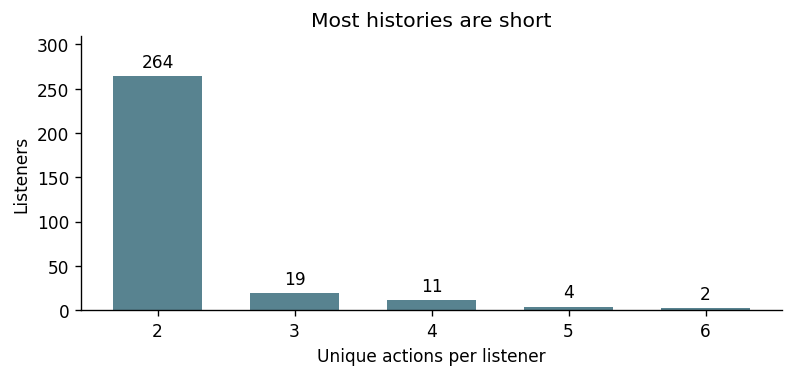

In [4]:
activity = clean.groupby("subject_id").size().rename("unique_events")
per_user = users.merge(activity, on="subject_id", how="left", validate="one_to_one")
per_user["unique_events"] = per_user.unique_events.fillna(0).astype(int)
frequency = per_user.unique_events.value_counts().sort_index()
summary = pd.DataFrame({"listeners": frequency, "share_pct": (100 * frequency / len(users)).round(1)})
print(summary.to_string())
print("Median actions per listener:", per_user.unique_events.median())
fig, ax = plt.subplots(figsize=(6.6, 3.2))
bars = ax.bar(frequency.index, frequency, color="#588390", width=0.65)
ax.bar_label(bars, padding=3)
ax.set(title="Most histories are short", xlabel="Unique actions per listener", ylabel="Listeners")
ax.set_xticks(frequency.index)
ax.set_ylim(0, frequency.max() * 1.17)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

264 of 300 listeners (88%) have exactly two unique events. This explains why a single play makes weak evidence of a lasting taste. The app keeps it as an episode. Three independent positive sessions can promote an inferred preference under the workbook policy.

## 4. Does the source mix change by surface?

The table reports counts. Each bar uses its own surface total as the denominator so that the shares can be compared directly.

source_class     explicit_user  product_signal
surface                                       
listening_ai               190              22
memory_controls             19               0
playlist_ai                188              26
podcast_ai                 189              27


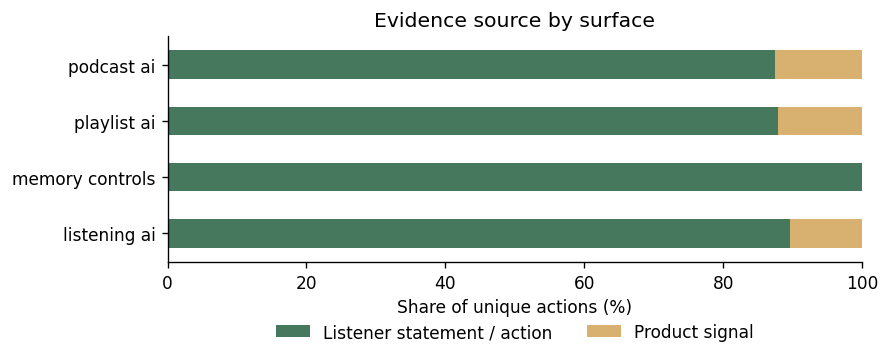

In [5]:
surface_counts = pd.crosstab(clean.surface, clean.source_class)
print(surface_counts.to_string())
surface_pct = surface_counts.div(surface_counts.sum(axis=1), axis=0) * 100
surface_pct.index = surface_pct.index.str.replace("_", " ")
ax = surface_pct.plot.barh(stacked=True, figsize=(7.4, 3.4), color=["#46785e", "#d8b06f"])
ax.set(xlim=(0, 100), xlabel="Share of unique actions (%)", ylabel="", title="Evidence source by surface")
ax.legend(["Listener statement / action", "Product signal"], loc="lower center", bbox_to_anchor=(0.5, -0.42),
          ncol=2, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.figure.tight_layout()
plt.show()

Product signals account for about 10.4% of listening, 12.1% of playlist, and 12.5% of podcast actions. All 19 memory-control actions come directly from listeners. Source class alone does not decide whether an action becomes a durable preference.

## 5. Timing, confidence and the experiment split

In [6]:
started = pd.to_datetime(clean.event_at, format="ISO8601", utc=True)
received = pd.to_datetime(clean.received_at, format="ISO8601", utc=True)
delay = (received - started).dt.total_seconds() * 1000
print("Event-to-intake delay in milliseconds")
print(delay.quantile([0.50, 0.90, 0.95]).round(0).to_string())
print("Negative delays:", (delay < 0).sum())
print("\nReference confidence by memory type")
print(memories.groupby("memory_type").confidence.agg(["count", "median"]).round(2).to_string())
print("\nAssigned cohorts")
print(pd.crosstab(users.cohort, users.primary_surface).to_string())
print("\nActions per assigned listener")
print(per_user.groupby("cohort").unique_events.agg(["count", "mean", "median"]).round(2).to_string())

Event-to-intake delay in milliseconds
0.50     886.0
0.90    1630.0
0.95    1734.0
Negative delays: 0

Reference confidence by memory type
                      count  median
memory_type                        
candidate_preference      6    0.49
episode                  53    0.90
exclusion                32    0.95
explicit_preference     183    0.95
inferred_preference       3    0.83

Assigned cohorts
primary_surface  listening_ai  playlist_ai  podcast_ai
cohort                                                
memory_disabled            50           50          50
memory_enabled             50           50          50

Actions per assigned listener
                 count  mean  median
cohort                              
memory_disabled    150  2.19     2.0
memory_enabled     150  2.21     2.0


The event-to-intake delay has a median of 886 ms and a 95th percentile of 1,734 ms. The project's 250 ms target times a different operation, a retrieval request. The API benchmark measures that separately.

There are only three inferred-preference reference records. Their median confidence of 0.83 describes the fixture scores. It is too little data to estimate a real probability of preference. Both experiment arms have 50 listeners per surface. Their median event count is two. Assigned cohorts and synthetic interactions cannot establish a retention or satisfaction uplift.

## 6. What does memory change for one matched request?

In [7]:
pair = gold[gold.case_id.isin(["G0002", "G0081"])].copy()
print(pair[["case_id", "subject_id", "query_query_at", "query_evaluation_mode",
            "expected_context_ids", "expected_policy_outcome"]].fillna("none").to_string(index=False))

case_id subject_id       query_query_at query_evaluation_mode expected_context_ids expected_policy_outcome
  G0002      U0002 2026-10-22T00:53:00Z        memory_enabled    M0002-01|M0002-02                 allowed
  G0081      U0002 2026-10-22T00:53:00Z       memory_disabled                 none     experiment_disabled


The same U0002 request, history and clock produce two expected context IDs with memory on and an empty context with memory off. This is a controlled retrieval comparison. The app's Quality review shows the actual replay results for these two cases. Measuring whether a listener returned more often would require repeated visits from real participants.